# 04 - Validation Framework & Baseline

This notebook implements a fixed time-based validation framework
and evaluates a weekly Seasonal Naive baseline.

Main objectives:
1. Define and validate three fixed 16-day validation folds.
2. Implement the RMSLE evaluation metric.
3. Build a recursive Seasonal Naive forecasting baseline.
4. Prevent validation target leakage.
5. Analyze model performance by fold, forecast horizon and family.
6. Save validation metrics and OOF predictions.

All future models must use the same validation folds
and evaluation protocol.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)


Pandas: 3.1.1
NumPy: 2.5.4


In [2]:
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    (path for path in candidates if (path / "data" / "raw" / "train.csv").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Cannot find data/raw/train.csv. Open this notebook from the project directory."
    )

RAW_DIR = ROOT / "data" / "raw"
VALIDATION_DIR = ROOT / "reports" / "validation"
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Raw data:", RAW_DIR)
print("Validation reports:", VALIDATION_DIR)


Project root: d:\STORE-SALES-TIME-SERIES-FORECASTING-KAGGLE-
Raw data: d:\STORE-SALES-TIME-SERIES-FORECASTING-KAGGLE-\data\raw
Validation reports: d:\STORE-SALES-TIME-SERIES-FORECASTING-KAGGLE-\reports\validation


In [3]:
# Use the original train data: Seasonal Naive only needs historical sales.
train = pd.read_csv(
    RAW_DIR / "train.csv",
    parse_dates=["date"],
    low_memory=False,
)

print("Train shape:", train.shape)
display(train.head())
train.info()


Train shape: (3000888, 6)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int64         
 1   date         datetime64[us]
 2   store_nbr    int64         
 3   family       str           
 4   sales        float64       
 5   onpromotion  int64         
dtypes: datetime64[us](1), float64(1), int64(3), str(1)
memory usage: 168.2 MB


In [4]:
print("Date range:", train.date.min(), "->", train.date.max())
print("Number of stores:", train.store_nbr.nunique())
print("Number of families:", train.family.nunique())
N_SERIES = train[["store_nbr", "family"]].drop_duplicates().shape[0]
print("Number of Store-Family series:", N_SERIES)
print("Missing sales:", int(train.sales.isna().sum()))
print("Negative sales:", int(train.sales.lt(0).sum()))
print(
    "Duplicate business keys:",
    int(train.duplicated(["date", "store_nbr", "family"]).sum()),
)

assert train.sales.notna().all(), "Sales contains missing values."
assert train.sales.ge(0).all(), "Sales contains negative values."
assert not train.duplicated(["date", "store_nbr", "family"]).any(), (
    "Duplicate business keys detected."
)
assert train.store_nbr.nunique() == 54, "Expected 54 stores."
assert train.family.nunique() == 33, "Expected 33 families."
assert N_SERIES == 1782, "Expected 1,782 Store-Family series."


Date range: 2013-01-01 00:00:00 -> 2017-08-15 00:00:00
Number of stores: 54
Number of families: 33
Number of Store-Family series: 1782
Missing sales: 0
Negative sales: 0
Duplicate business keys: 0


In [5]:
# These dates are fixed for every model comparison. Do not tune folds to scores.
FOLDS = [
    {
        "fold": "fold_1",
        "train_end": "2016-07-30",
        "valid_start": "2016-07-31",
        "valid_end": "2016-08-15",
    },
    {
        "fold": "fold_2",
        "train_end": "2017-06-30",
        "valid_start": "2017-07-01",
        "valid_end": "2017-07-16",
    },
    {
        "fold": "fold_3",
        "train_end": "2017-07-30",
        "valid_start": "2017-07-31",
        "valid_end": "2017-08-15",
    },
]
for fold in FOLDS:
    for column in ["train_end", "valid_start", "valid_end"]:
        fold[column] = pd.Timestamp(fold[column])

FOLD_DAYS = 16
fold_table = pd.DataFrame(FOLDS)
display(fold_table)


,fold,train_end,valid_start,valid_end
0,fold_1,2016-07-30,2016-07-31,2016-08-15
1,fold_2,2017-06-30,2017-07-01,2017-07-16
2,fold_3,2017-07-30,2017-07-31,2017-08-15


## Check each validation fold

Each validation window must contain 16 consecutive dates and exactly 1,782 Store-Family observations on every date (28,512 rows total). Training data must end before validation begins. The checks below use the raw data and do not use validation target values to make predictions.


In [6]:
fold_checks = []
for fold in FOLDS:
    train_fold = train.loc[train.date.le(fold["train_end"])]
    valid_fold = train.loc[
        train.date.between(fold["valid_start"], fold["valid_end"])
    ]
    expected_dates = pd.date_range(
        fold["valid_start"], fold["valid_end"], freq="D"
    )
    actual_dates = pd.DatetimeIndex(valid_fold.date.drop_duplicates().sort_values())
    daily_rows = valid_fold.groupby("date").size().reindex(expected_dates, fill_value=0)
    daily_series = (
        valid_fold.groupby("date")[["store_nbr", "family"]]
        .apply(lambda frame: frame.drop_duplicates().shape[0])
        .reindex(expected_dates, fill_value=0)
    )
    n_valid_dates = int(actual_dates.size)
    n_valid_rows = int(len(valid_fold))
    checks = {
        "fold": fold["fold"],
        "train_rows": int(len(train_fold)),
        "valid_rows": n_valid_rows,
        "valid_dates": n_valid_dates,
        "expected_valid_rows": FOLD_DAYS * N_SERIES,
        "dates_are_consecutive": actual_dates.equals(expected_dates),
        "rows_match_expected": n_valid_rows == FOLD_DAYS * N_SERIES,
        "all_dates_have_all_series": daily_series.eq(N_SERIES).all(),
        "daily_row_counts_are_complete": daily_rows.eq(N_SERIES).all(),
        "training_precedes_validation": fold["train_end"] < fold["valid_start"],
    }
    fold_checks.append(checks)

fold_check_df = pd.DataFrame(fold_checks)
display(fold_check_df)

check_columns = [column for column in fold_check_df.columns if column != "fold"]
assert fold_check_df[check_columns].all().all(), (
    "At least one validation fold integrity check failed. Inspect fold_check_df."
)


,fold,train_rows,valid_rows,valid_dates,expected_valid_rows,dates_are_consecutive,rows_match_expected,all_dates_have_all_series,daily_row_counts_are_complete,training_precedes_validation
0,fold_1,2323728,28512,16,28512,True,True,True,True,True
1,fold_2,2918916,28512,16,28512,True,True,True,True,True
2,fold_3,2972376,28512,16,28512,True,True,True,True,True


## Check seven historical days before each fold

The weekly seasonal baseline needs the seven days immediately before validation. Confirm that all 1,782 series are present on each of those dates. This check also makes gaps in the required history visible before forecasting is implemented.


In [7]:
history_checks = []
for fold in FOLDS:
    train_fold = train.loc[train.date.le(fold["train_end"])]
    history_dates = pd.date_range(
        end=fold["valid_start"] - pd.Timedelta(days=1),
        periods=7,
        freq="D",
    )
    history_counts = (
        train_fold.loc[train_fold.date.isin(history_dates)]
        .groupby("date")
        .size()
        .reindex(history_dates, fill_value=0)
    )
    history_checks.append(
        {
            "fold": fold["fold"],
            "history_start": history_dates.min(),
            "history_end": history_dates.max(),
            "history_dates": len(history_dates),
            "all_7_days_available": history_counts.eq(N_SERIES).all(),
            "minimum_series_per_day": int(history_counts.min()),
            "expected_series_per_day": N_SERIES,
        }
    )

history_check_df = pd.DataFrame(history_checks)
display(history_check_df)
assert history_check_df["all_7_days_available"].all(), (
    "Required seven-day history is incomplete. Inspect history_check_df."
)


,fold,history_start,history_end,history_dates,all_7_days_available,minimum_series_per_day,expected_series_per_day
0,fold_1,2016-07-24,2016-07-30,7,True,1782,1782
1,fold_2,2017-06-24,2017-06-30,7,True,1782,1782
2,fold_3,2017-07-24,2017-07-30,7,True,1782,1782


## Stage 1 checkpoint

Before moving to the metric and Seasonal Naive baseline, review `fold_check_df` and `history_check_df`:

- Three fixed folds, each with 16 validation dates.
- 28,512 validation rows per fold and 1,782 series per date.
- Seven complete historical dates before each validation window.
- No duplicate `(date, store_nbr, family)` keys and no missing or negative sales.

Do not change fold dates to improve a score. The next stage will add RMSLE, recursive forecasting, OOF predictions, error analysis, and saved validation reports after this protocol is reviewed.


## Part B - RMSLE metric

The competition metric compares predictions and actual sales after applying `log1p`. Lower RMSLE is better. Actual target values must remain unchanged; only negative predictions are clipped to zero.


In [8]:
def rmsle(y_true, y_pred):
    """Compute RMSLE after validating shapes and finite non-negative targets."""
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)

    if y_true.shape != y_pred.shape:
        raise ValueError("y_true and y_pred must have the same shape.")
    if not np.isfinite(y_true).all():
        raise ValueError("y_true contains NaN or infinity.")
    if not np.isfinite(y_pred).all():
        raise ValueError("y_pred contains NaN or infinity.")
    if (y_true < 0).any():
        raise ValueError("y_true must be non-negative.")

    y_pred = np.clip(y_pred, 0, None)
    log_error = np.log1p(y_pred) - np.log1p(y_true)
    return float(np.sqrt(np.mean(log_error ** 2)))


In [9]:
# A small smoke check for the metric implementation.
y_true_test = np.array([0, 10, 100, 1000], dtype=np.float64)
y_pred_test = np.array([0, 12, 90, 1100], dtype=np.float64)
score = rmsle(y_true_test, y_pred_test)
print("Test RMSLE:", score)
assert np.isfinite(score) and score >= 0


Test RMSLE: 0.10936652995958641


## Part C - Recursive Seasonal Naive baseline

The weekly Seasonal Naive forecast is `y_hat(t) = y(t - 7)`. The forecasting function below receives only pre-validation history and the validation calendar. For horizons after day 7, it reads forecasts previously added to its local history. It never receives validation actual sales.


In [10]:
def seasonal_naive_recursive(
    train_history,
    valid_dates,
    series_keys,
    season_length=7,
):
    """Forecast recursively using only past observations and prior predictions."""
    valid_dates = pd.DatetimeIndex(valid_dates)
    if len(valid_dates) == 0:
        raise ValueError("valid_dates is empty.")
    if not valid_dates.is_monotonic_increasing or valid_dates.has_duplicates:
        raise ValueError("valid_dates must be sorted and unique.")
    if season_length < 1:
        raise ValueError("season_length must be positive.")
    if not train_history.date.lt(valid_dates[0]).all():
        raise ValueError("train_history must contain dates strictly before validation.")

    key_index = pd.MultiIndex.from_frame(series_keys[["store_nbr", "family"]])
    if key_index.has_duplicates:
        raise ValueError("series_keys contains duplicate Store-Family keys.")

    expected_history_dates = pd.date_range(
        end=valid_dates[0] - pd.Timedelta(days=1),
        periods=season_length,
        freq="D",
    )
    history_window = train_history.loc[
        train_history.date.isin(expected_history_dates),
        ["date", "store_nbr", "family", "sales"],
    ]
    history_by_date = {}
    for date, frame in history_window.groupby("date", sort=False):
        values = frame.set_index(["store_nbr", "family"])["sales"].reindex(key_index)
        if values.isna().any():
            raise ValueError(f"Incomplete historical series on {date:%Y-%m-%d}.")
        history_by_date[pd.Timestamp(date)] = values.to_numpy(dtype=np.float64)

    if set(history_by_date) != set(expected_history_dates):
        raise ValueError("The required pre-validation history dates are incomplete.")

    prediction_frames = []
    for horizon, current_date in enumerate(valid_dates, start=1):
        source_date = current_date - pd.Timedelta(days=season_length)
        if source_date not in history_by_date:
            raise ValueError(f"No observed or forecast history for {source_date:%Y-%m-%d}.")
        y_pred = np.clip(history_by_date[source_date], 0, None)

        frame = series_keys[["store_nbr", "family"]].copy()
        frame["date"] = current_date
        frame["horizon"] = horizon
        frame["sales_pred"] = y_pred
        prediction_frames.append(frame)

        # Add predictions only. Validation actual sales are not available in this function.
        history_by_date[current_date] = y_pred.copy()

    return pd.concat(prediction_frames, ignore_index=True)


In [11]:
series_keys = (
    train[["store_nbr", "family"]]
    .drop_duplicates()
    .sort_values(["store_nbr", "family"])
    .reset_index(drop=True)
)
fold_predictions = []
fold_metrics = []

for fold in FOLDS:
    print(f"\nRunning {fold['fold']}...")
    train_history = train.loc[
        train.date.le(fold["train_end"]),
        ["date", "store_nbr", "family", "sales"],
    ].copy()
    valid_dates = pd.date_range(
        fold["valid_start"], fold["valid_end"], freq="D"
    )

    # Generate every prediction before reading validation target values.
    predictions = seasonal_naive_recursive(
        train_history=train_history,
        valid_dates=valid_dates,
        series_keys=series_keys,
        season_length=7,
    )
    valid_actual = train.loc[
        train.date.between(fold["valid_start"], fold["valid_end"]),
        ["date", "store_nbr", "family", "sales"],
    ].rename(columns={"sales": "sales_true"})
    evaluated = valid_actual.merge(
        predictions,
        on=["date", "store_nbr", "family"],
        how="inner",
        validate="one_to_one",
    )

    expected_rows = FOLD_DAYS * len(series_keys)
    assert len(predictions) == expected_rows
    assert len(valid_actual) == expected_rows
    assert len(evaluated) == expected_rows
    fold_score = rmsle(evaluated.sales_true, evaluated.sales_pred)
    evaluated["fold"] = fold["fold"]
    fold_predictions.append(evaluated)
    fold_metrics.append(
        {
            "fold": fold["fold"],
            "train_end": fold["train_end"],
            "valid_start": fold["valid_start"],
            "valid_end": fold["valid_end"],
            "n_predictions": len(evaluated),
            "rmsle": fold_score,
        }
    )
    print("Predictions:", len(evaluated))
    print("RMSLE:", fold_score)



Running fold_1...
Predictions: 28512
RMSLE: 0.5882480840577329

Running fold_2...
Predictions: 28512
RMSLE: 0.5110969009798504

Running fold_3...
Predictions: 28512
RMSLE: 0.6170404161294091


## Part D - Baseline result analysis

Compare folds as diagnostics. Differences can suggest that forecast difficulty changes over time, but the scores alone do not explain why.


In [12]:
fold_metrics_df = pd.DataFrame(fold_metrics)
display(fold_metrics_df)

oof_predictions = pd.concat(fold_predictions, ignore_index=True)
mean_fold_rmsle = fold_metrics_df["rmsle"].mean()
pooled_oof_rmsle = rmsle(
    oof_predictions["sales_true"],
    oof_predictions["sales_pred"],
)
print("Mean Fold RMSLE:", mean_fold_rmsle)
print("Pooled OOF RMSLE:", pooled_oof_rmsle)
print("Total OOF predictions:", len(oof_predictions))
assert len(oof_predictions) == len(FOLDS) * FOLD_DAYS * len(series_keys)


,fold,train_end,valid_start,valid_end,n_predictions,rmsle
0,fold_1,2016-07-30,2016-07-31,2016-08-15,28512,0.588248
1,fold_2,2017-06-30,2017-07-01,2017-07-16,28512,0.511097
2,fold_3,2017-07-30,2017-07-31,2017-08-15,28512,0.617040


Mean Fold RMSLE: 0.5721284670556641
Pooled OOF RMSLE: 0.5738741806720223
Total OOF predictions: 85536


,horizon,mean_squared_log_error,n_predictions,rmsle
0,1,0.288176,5346,0.536820
1,2,0.325309,5346,0.570359
2,3,0.336017,5346,0.579669
3,4,0.323777,5346,0.569014
4,5,0.315522,5346,0.561714
5,6,0.294791,5346,0.542947
6,7,0.281094,5346,0.530183
7,8,0.303044,5346,0.550494
8,9,0.317130,5346,0.563143
9,10,0.328574,5346,0.573213


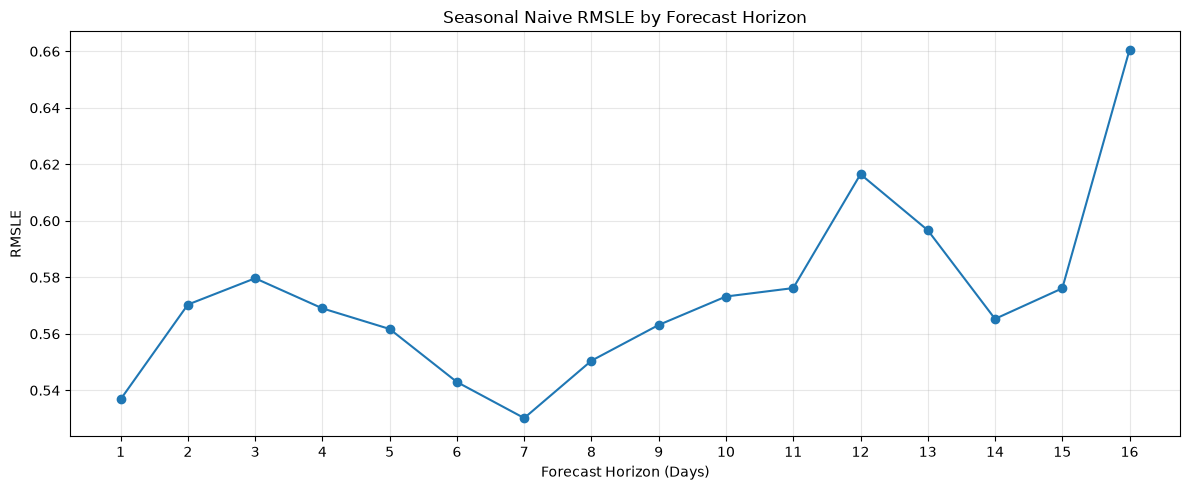

In [13]:
oof_predictions["squared_log_error"] = (
    np.log1p(oof_predictions["sales_pred"])
    - np.log1p(oof_predictions["sales_true"])
) ** 2
horizon_summary = (
    oof_predictions.groupby("horizon")
    .agg(
        mean_squared_log_error=("squared_log_error", "mean"),
        n_predictions=("sales_true", "size"),
    )
    .reset_index()
)
horizon_summary["rmsle"] = np.sqrt(horizon_summary["mean_squared_log_error"])
display(horizon_summary)

plt.figure(figsize=(12, 5))
plt.plot(horizon_summary["horizon"], horizon_summary["rmsle"], marker="o")
plt.title("Seasonal Naive RMSLE by Forecast Horizon")
plt.xlabel("Forecast Horizon (Days)")
plt.ylabel("RMSLE")
plt.xticks(range(1, FOLD_DAYS + 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


,family,mean_squared_log_error,n_predictions,mean_actual_sales,rmsle
31,SCHOOL AND OFFICE SUPPLIES,1.555706,2592,22.091049,1.247280
13,GROCERY II,0.835063,2592,26.229552,0.913818
21,LINGERIE,0.789607,2592,6.619985,0.888598
14,HARDWARE,0.566091,2592,1.401235,0.752390
6,CELEBRATION,0.511858,2592,13.329090,0.715443
23,MAGAZINES,0.501590,2592,6.368056,0.708230
0,AUTOMOTIVE,0.492061,2592,7.293210,0.701471
2,BEAUTY,0.475759,2592,6.187886,0.689753
22,"LIQUOR,WINE,BEER",0.459822,2592,97.552855,0.678102
15,HOME AND KITCHEN I,0.451217,2592,31.070216,0.671727


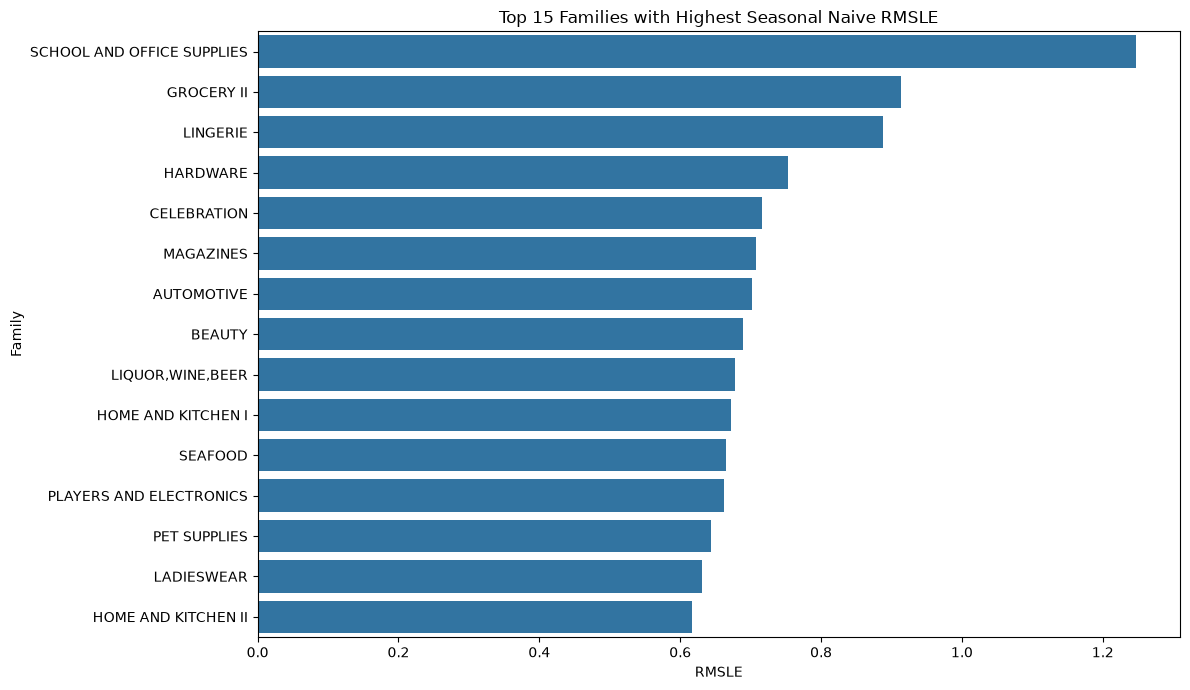

In [14]:
family_summary = (
    oof_predictions.groupby("family")
    .agg(
        mean_squared_log_error=("squared_log_error", "mean"),
        n_predictions=("sales_true", "size"),
        mean_actual_sales=("sales_true", "mean"),
    )
    .reset_index()
)
family_summary["rmsle"] = np.sqrt(family_summary["mean_squared_log_error"])
family_summary = family_summary.sort_values("rmsle", ascending=False)
display(family_summary)

top_error_families = family_summary.head(15)
plt.figure(figsize=(12, 7))
sns.barplot(data=top_error_families, x="rmsle", y="family")
plt.title("Top 15 Families with Highest Seasonal Naive RMSLE")
plt.xlabel("RMSLE")
plt.ylabel("Family")
plt.tight_layout()
plt.show()


## Part E - Save validation reports

The following outputs are generated only when you run the notebook. Review the actual results before filling the conclusion; do not insert expected or guessed scores.


In [15]:
fold_table.to_csv(VALIDATION_DIR / "validation_folds.csv", index=False)
fold_metrics_df.to_csv(
    VALIDATION_DIR / "seasonal_naive_fold_metrics.csv", index=False
)
oof_predictions[
    [
        "fold",
        "horizon",
        "date",
        "store_nbr",
        "family",
        "sales_true",
        "sales_pred",
    ]
].to_csv(VALIDATION_DIR / "seasonal_naive_oof_predictions.csv", index=False)
horizon_summary.to_csv(
    VALIDATION_DIR / "seasonal_naive_horizon_metrics.csv", index=False
)
family_summary.to_csv(
    VALIDATION_DIR / "seasonal_naive_family_metrics.csv", index=False
)
summary_metrics = pd.DataFrame(
    [
        {"metric": "mean_fold_rmsle", "value": mean_fold_rmsle},
        {"metric": "pooled_oof_rmsle", "value": pooled_oof_rmsle},
        {"metric": "total_oof_predictions", "value": len(oof_predictions)},
    ]
)
summary_metrics.to_csv(
    VALIDATION_DIR / "seasonal_naive_summary_metrics.csv", index=False
)
print("Validation reports saved to:", VALIDATION_DIR)


Validation reports saved to: d:\STORE-SALES-TIME-SERIES-FORECASTING-KAGGLE-\reports\validation


# Conclusion - Validation Framework & Seasonal Naive Baseline

## 1. Validation Strategy
- Expanding-window validation with three fixed folds.
- Forecast horizon: 16 days.
- Each fold contains 28,512 predictions.
- Total OOF predictions: 85,536.

## 2. Validation Integrity
- All validation dates are complete.
- All 1,782 Store-Family series are represented.
- Seven historical dates are available before each fold.
- Business keys are unique.
- Validation actual sales are used only for evaluation.

## 3. Seasonal Naive Baseline
- Forecasting rule: y_hat(t) = y(t - 7).
- Recursive forecasts are generated across all 16 horizons.
- Previous predictions, not actual validation sales, update forecast history.
- No validation target leakage was identified.

## 4. Evaluation Results
- Fold 1 RMSLE: 0.588248
- Fold 2 RMSLE: 0.511097
- Fold 3 RMSLE: 0.617040
- Mean Fold RMSLE: 0.572128
- Pooled OOF RMSLE: 0.573874

## 5. Error Analysis
- Highest RMSLE horizon: Day 16 (0.660553).
- Lowest RMSLE horizon: Day 7 (0.530183).
- Most difficult family: SCHOOL AND OFFICE SUPPLIES (1.247280).
- Lowest family RMSLE: BOOKS (0.115446).
- BOOKS has extremely low average sales, so its low RMSLE should be interpreted with its sparse target distribution in mind.

## 6. Next Steps
- Keep the validation framework and folds fixed.
- Use Seasonal Naive as the first baseline for model comparisons.
- Implement Global LightGBM with the same validation protocol.
- Compare all future models using pooled OOF RMSLE and fold-level metrics.

# Stage 3-6 - Global LightGBM, recursive validation, comparison

This section uses one global LightGBM model per fold for all Store-Family series. The initial feature set is limited to exact calendar sales lags, prior rolling means, calendar fields, promotion, and store/family metadata. Transactions, oil, and holidays are intentionally excluded from this first baseline.

For each fold, the model is trained only through that fold's cutoff. It then forecasts each of the next 16 dates recursively. Validation sales are read only after all 16 predictions have been generated, for scoring and error analysis.


In [16]:
import json
import gc
import lightgbm as lgb

print("LightGBM:", lgb.__version__)


LightGBM: 4.7.0


## Feature construction

Lag values are joined by the exact source calendar date (`target_date - lag_days`), so a missing Christmas record cannot shift later values by one row. Rolling features use time-based windows ending before the target date. During recursive forecasting, the history contains only pre-cutoff actuals and earlier predictions.


In [17]:
LAG_DAYS = [7, 14, 21, 28]
ROLLING_WINDOWS = [7, 28]
CATEGORICAL_FEATURES = ["store_nbr", "family", "city", "state", "type", "cluster"]
FEATURE_COLUMNS = (
    [f"lag_{days}" for days in LAG_DAYS]
    + [f"rolling_mean_{days}" for days in ROLLING_WINDOWS]
    + ["dayofweek", "month", "day", "is_weekend", "onpromotion"]
    + CATEGORICAL_FEATURES
)

stores = pd.read_csv(RAW_DIR / "stores.csv")
store_metadata = stores[["store_nbr", "city", "state", "type", "cluster"]].copy()


def build_feature_rows(history, target_rows, store_metadata):
    """Create leakage-safe features for the supplied target dates."""
    keys = ["store_nbr", "family"]
    base = target_rows[["date", *keys, "onpromotion"]].copy()
    base["_feature_row_order"] = np.arange(len(base))
    base["dayofweek"] = base.date.dt.day_of_week.astype("int8")
    base["month"] = base.date.dt.month.astype("int8")
    base["day"] = base.date.dt.day.astype("int8")
    base["is_weekend"] = base.dayofweek.isin([5, 6]).astype("int8")

    history_lookup = history[["date", *keys, "sales"]].copy()
    for lag in LAG_DAYS:
        lag_lookup = history_lookup.copy()
        lag_lookup["date"] = lag_lookup.date + pd.Timedelta(days=lag)
        lag_lookup = lag_lookup.rename(columns={"sales": f"lag_{lag}"})
        base = base.merge(
            lag_lookup,
            on=["date", *keys],
            how="left",
            validate="one_to_one",
        )

    if base.date.nunique() == 1:
        target_date = base.date.iloc[0]
        for window in ROLLING_WINDOWS:
            window_history = history.loc[
                history.date.ge(target_date - pd.Timedelta(days=window))
                & history.date.lt(target_date)
            ]
            rolling = (
                window_history.groupby(keys, as_index=False).sales.mean()
                .rename(columns={"sales": f"rolling_mean_{window}"})
            )
            base = base.merge(rolling, on=keys, how="left", validate="one_to_one")
    else:
        rolling_parts = []
        for (store_nbr, family), group in history.groupby(keys, sort=False):
            series = group.sort_values("date").set_index("date")["sales"]
            part = pd.DataFrame({"date": series.index})
            for window in ROLLING_WINDOWS:
                part[f"rolling_mean_{window}"] = (
                    series.rolling(
                        f"{window}D", closed="left", min_periods=1
                    ).mean().to_numpy()
                )
            part["store_nbr"] = store_nbr
            part["family"] = family
            rolling_parts.append(part)
        rolling_features = pd.concat(rolling_parts, ignore_index=True)
        base = base.merge(
            rolling_features,
            on=["date", *keys],
            how="left",
            validate="one_to_one",
        )

    base = base.merge(
        store_metadata,
        on="store_nbr",
        how="left",
        validate="many_to_one",
    )
    base = base.sort_values("_feature_row_order").drop(columns="_feature_row_order")
    return base


def prepare_model_matrix(feature_frame, category_levels=None):
    """Select model columns and align categorical levels across forecast dates."""
    matrix = feature_frame[FEATURE_COLUMNS].copy()
    if category_levels is None:
        category_levels = {
            column: pd.Index(matrix[column].dropna().unique()).sort_values()
            for column in CATEGORICAL_FEATURES
        }
    for column in CATEGORICAL_FEATURES:
        matrix[column] = pd.Categorical(
            matrix[column], categories=category_levels[column]
        )
    return matrix, category_levels


## Fit and recursively validate one LightGBM model per fold

The first baseline uses fixed parameters rather than early stopping on validation targets. The target is `log1p(sales)`; predictions are converted back with `expm1` and clipped at zero. Categorical levels are fixed from each fold's training matrix and reused for every forecast date.


In [18]:
LGBM_PARAMS = {
    "objective": "regression",
    "n_estimators": 500,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "colsample_bytree": 0.8,
    "reg_lambda": 1.0,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1,
}

lightgbm_fold_predictions = []
lightgbm_fold_metrics = []
lightgbm_importance_parts = []

for fold in FOLDS:
    print(f"\nTraining and forecasting {fold['fold']}...")
    fold_train = train.loc[train.date.le(fold["train_end"])].copy()
    training_rows = fold_train.loc[
        fold_train.date.ge(fold_train.date.min() + pd.Timedelta(days=28)),
        ["date", "store_nbr", "family", "onpromotion", "sales"],
    ].copy()

    train_features = build_feature_rows(
        history=fold_train[["date", "store_nbr", "family", "sales"]],
        target_rows=training_rows,
        store_metadata=store_metadata,
    )
    X_train, category_levels = prepare_model_matrix(train_features)
    y_train = np.log1p(training_rows.sales.to_numpy(dtype=np.float64))
    model = lgb.LGBMRegressor(**LGBM_PARAMS)
    model.fit(X_train, y_train, categorical_feature=CATEGORICAL_FEATURES)

    # Forecast loop sees future date, promotion, and metadata only.
    recursive_history = fold_train[["date", "store_nbr", "family", "sales"]].copy()
    valid_dates = pd.date_range(fold["valid_start"], fold["valid_end"], freq="D")
    fold_prediction_parts = []
    for horizon, current_date in enumerate(valid_dates, start=1):
        known_future = train.loc[
            train.date.eq(current_date),
            ["date", "store_nbr", "family", "onpromotion"],
        ].copy()
        current_features = build_feature_rows(
            history=recursive_history,
            target_rows=known_future,
            store_metadata=store_metadata,
        )
        X_current, _ = prepare_model_matrix(current_features, category_levels)
        predicted_log_sales = model.predict(X_current)
        predicted_sales = np.clip(np.expm1(predicted_log_sales), 0, None)

        prediction_frame = known_future[["date", "store_nbr", "family"]].copy()
        prediction_frame["horizon"] = horizon
        prediction_frame["sales_pred"] = predicted_sales
        fold_prediction_parts.append(prediction_frame)

        # Only the prediction is appended. Actual validation sales are never appended.
        history_update = prediction_frame[["date", "store_nbr", "family"]].copy()
        history_update["sales"] = predicted_sales
        recursive_history = pd.concat(
            [recursive_history, history_update], ignore_index=True
        )

    predictions = pd.concat(fold_prediction_parts, ignore_index=True)
    valid_actual = train.loc[
        train.date.between(fold["valid_start"], fold["valid_end"]),
        ["date", "store_nbr", "family", "sales"],
    ].rename(columns={"sales": "sales_true"})
    evaluated = valid_actual.merge(
        predictions,
        on=["date", "store_nbr", "family"],
        how="inner",
        validate="one_to_one",
    )
    expected_rows = FOLD_DAYS * N_SERIES
    assert len(predictions) == expected_rows
    assert len(valid_actual) == expected_rows
    assert len(evaluated) == expected_rows

    fold_score = rmsle(evaluated.sales_true, evaluated.sales_pred)
    evaluated["fold"] = fold["fold"]
    lightgbm_fold_predictions.append(evaluated)
    lightgbm_fold_metrics.append(
        {
            "fold": fold["fold"],
            "train_end": fold["train_end"],
            "valid_start": fold["valid_start"],
            "valid_end": fold["valid_end"],
            "n_predictions": len(evaluated),
            "rmsle": fold_score,
        }
    )
    lightgbm_importance_parts.append(
        pd.DataFrame(
            {
                "fold": fold["fold"],
                "feature": FEATURE_COLUMNS,
                "gain": model.booster_.feature_importance(importance_type="gain"),
                "split": model.booster_.feature_importance(importance_type="split"),
            }
        )
    )
    print("Predictions:", len(evaluated))
    print("RMSLE:", fold_score)

    del model, X_train, train_features, fold_train, recursive_history
    gc.collect()



Training and forecasting fold_1...
Predictions: 28512
RMSLE: 0.5697949173796084

Training and forecasting fold_2...
Predictions: 28512
RMSLE: 0.39073387503926416

Training and forecasting fold_3...
Predictions: 28512
RMSLE: 0.4370781393435949


## Evaluate LightGBM and compare with Seasonal Naive

The comparison reports each fold, mean fold RMSLE, and pooled OOF RMSLE. The percentage improvement is positive when LightGBM has a lower pooled RMSLE than Seasonal Naive.


In [19]:
lightgbm_fold_metrics_df = pd.DataFrame(lightgbm_fold_metrics)
lightgbm_oof_predictions = pd.concat(lightgbm_fold_predictions, ignore_index=True)
lightgbm_mean_fold_rmsle = lightgbm_fold_metrics_df.rmsle.mean()
lightgbm_pooled_oof_rmsle = rmsle(
    lightgbm_oof_predictions.sales_true,
    lightgbm_oof_predictions.sales_pred,
)
print("LightGBM mean fold RMSLE:", lightgbm_mean_fold_rmsle)
print("LightGBM pooled OOF RMSLE:", lightgbm_pooled_oof_rmsle)
print("LightGBM OOF predictions:", len(lightgbm_oof_predictions))

naive_fold_metrics = pd.read_csv(
    VALIDATION_DIR / "seasonal_naive_fold_metrics.csv"
)
naive_oof_predictions = pd.read_csv(
    VALIDATION_DIR / "seasonal_naive_oof_predictions.csv",
    parse_dates=["date"],
)
naive_mean_fold_rmsle = naive_fold_metrics.rmsle.mean()
naive_pooled_oof_rmsle = rmsle(
    naive_oof_predictions.sales_true,
    naive_oof_predictions.sales_pred,
)

model_comparison = pd.DataFrame(
    [
        {
            "model": "Seasonal Naive",
            **{
                fold: float(naive_fold_metrics.loc[naive_fold_metrics.fold.eq(fold), "rmsle"].iloc[0])
                for fold in ["fold_1", "fold_2", "fold_3"]
            },
            "mean_fold_rmsle": naive_mean_fold_rmsle,
            "pooled_oof_rmsle": naive_pooled_oof_rmsle,
        },
        {
            "model": "Global LightGBM",
            **{
                fold: float(lightgbm_fold_metrics_df.loc[lightgbm_fold_metrics_df.fold.eq(fold), "rmsle"].iloc[0])
                for fold in ["fold_1", "fold_2", "fold_3"]
            },
            "mean_fold_rmsle": lightgbm_mean_fold_rmsle,
            "pooled_oof_rmsle": lightgbm_pooled_oof_rmsle,
        },
    ]
)
model_comparison["pooled_improvement_pct_vs_naive"] = np.nan
model_comparison.loc[model_comparison.model.eq("Global LightGBM"), "pooled_improvement_pct_vs_naive"] = (
    (naive_pooled_oof_rmsle - lightgbm_pooled_oof_rmsle)
    / naive_pooled_oof_rmsle
    * 100
)
display(model_comparison)


LightGBM mean fold RMSLE: 0.4658689772541558
LightGBM pooled OOF RMSLE: 0.4720086541815708
LightGBM OOF predictions: 85536


,model,fold_1,fold_2,fold_3,mean_fold_rmsle,pooled_oof_rmsle,pooled_improvement_pct_vs_naive
0,Seasonal Naive,0.588248,0.511097,0.617040,0.572128,0.573874,NaN
1,Global LightGBM,0.569795,0.390734,0.437078,0.465869,0.472009,17.750498


In [20]:
lightgbm_oof_predictions["squared_log_error"] = (
    np.log1p(lightgbm_oof_predictions.sales_pred)
    - np.log1p(lightgbm_oof_predictions.sales_true)
) ** 2
lightgbm_horizon_summary = (
    lightgbm_oof_predictions.groupby("horizon")
    .agg(
        mean_squared_log_error=("squared_log_error", "mean"),
        n_predictions=("sales_true", "size"),
    )
    .reset_index()
)
lightgbm_horizon_summary["rmsle"] = np.sqrt(
    lightgbm_horizon_summary.mean_squared_log_error
)
display(lightgbm_horizon_summary)

lightgbm_family_summary = (
    lightgbm_oof_predictions.groupby("family")
    .agg(
        mean_squared_log_error=("squared_log_error", "mean"),
        n_predictions=("sales_true", "size"),
        mean_actual_sales=("sales_true", "mean"),
    )
    .reset_index()
)
lightgbm_family_summary["rmsle"] = np.sqrt(
    lightgbm_family_summary.mean_squared_log_error
)
lightgbm_family_summary = lightgbm_family_summary.sort_values(
    "rmsle", ascending=False
)
display(lightgbm_family_summary)


,horizon,mean_squared_log_error,n_predictions,rmsle
0,1,0.139224,5346,0.373127
1,2,0.180126,5346,0.424413
2,3,0.176773,5346,0.420443
3,4,0.168924,5346,0.411004
4,5,0.180702,5346,0.425091
5,6,0.210207,5346,0.458484
6,7,0.227811,5346,0.477295
7,8,0.201915,5346,0.449350
8,9,0.212639,5346,0.461128
9,10,0.212295,5346,0.460754


,family,mean_squared_log_error,n_predictions,mean_actual_sales,rmsle
30,PRODUCE,0.729105,2592,2288.349381,0.853877
6,CELEBRATION,0.476981,2592,13.329090,0.690638
13,GROCERY II,0.470950,2592,26.229552,0.686258
31,SCHOOL AND OFFICE SUPPLIES,0.412859,2592,22.091049,0.642541
21,LINGERIE,0.395105,2592,6.619985,0.628574
15,HOME AND KITCHEN I,0.362820,2592,31.070216,0.602345
19,LADIESWEAR,0.355992,2592,11.115741,0.596651
27,PLAYERS AND ELECTRONICS,0.352086,2592,11.217978,0.593369
23,MAGAZINES,0.332212,2592,6.368056,0.576379
26,PET SUPPLIES,0.311197,2592,8.248457,0.557851


,feature,mean_gain,mean_split
9,lag_7,1.137973e+08,1359.000000
13,rolling_mean_7,7.868802e+07,1993.666667
6,lag_14,1.065736e+06,600.333333
4,family,6.608394e+05,2305.000000
8,lag_28,4.245960e+05,581.333333
3,dayofweek,4.060829e+05,1321.000000
12,rolling_mean_28,3.800486e+05,981.333333
7,lag_21,3.476551e+05,442.333333
2,day,2.851842e+05,1638.333333
10,month,2.197626e+05,1261.000000


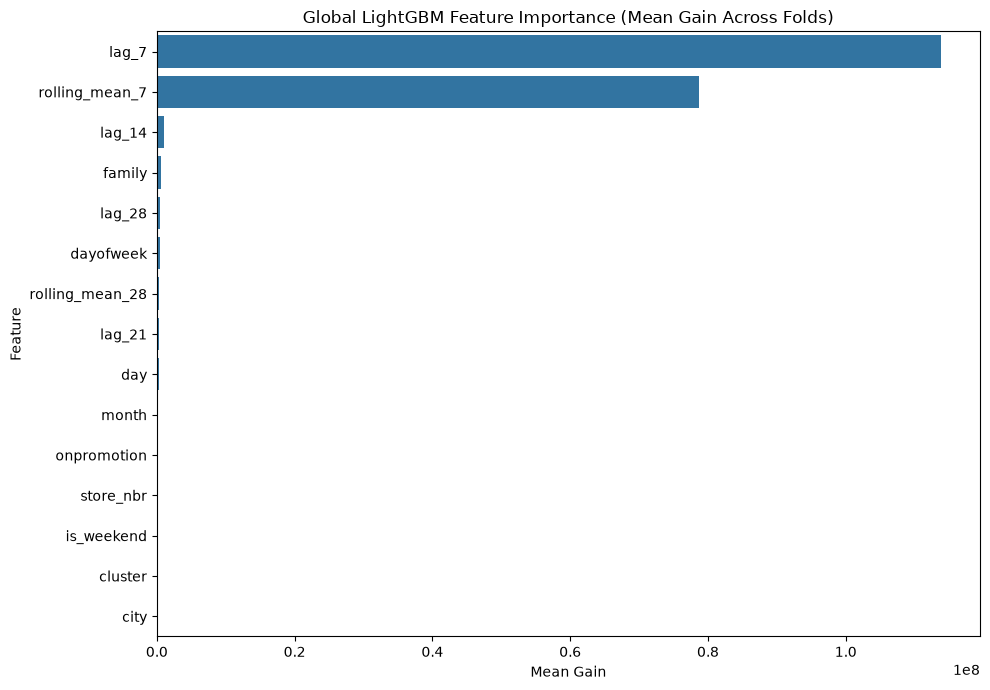

In [21]:
lightgbm_importance = pd.concat(lightgbm_importance_parts, ignore_index=True)
lightgbm_importance_summary = (
    lightgbm_importance.groupby("feature", as_index=False)
    .agg(mean_gain=("gain", "mean"), mean_split=("split", "mean"))
    .sort_values("mean_gain", ascending=False)
)
display(lightgbm_importance_summary)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=lightgbm_importance_summary.head(15),
    x="mean_gain",
    y="feature",
)
plt.title("Global LightGBM Feature Importance (Mean Gain Across Folds)")
plt.xlabel("Mean Gain")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## Stage 6 - Save the baseline comparison

These files are generated when you run this section. The configuration JSON records the feature list, transformation, model parameters, and the policy for recursive validation.


In [22]:
lightgbm_fold_metrics_df.to_csv(
    VALIDATION_DIR / "lightgbm_fold_metrics.csv", index=False
)
lightgbm_oof_predictions[
    [
        "fold", "horizon", "date", "store_nbr", "family",
        "sales_true", "sales_pred",
    ]
].to_csv(VALIDATION_DIR / "lightgbm_oof_predictions.csv", index=False)
lightgbm_horizon_summary.to_csv(
    VALIDATION_DIR / "lightgbm_horizon_metrics.csv", index=False
)
lightgbm_family_summary.to_csv(
    VALIDATION_DIR / "lightgbm_family_metrics.csv", index=False
)
lightgbm_importance_summary.to_csv(
    VALIDATION_DIR / "lightgbm_feature_importance.csv", index=False
)
model_comparison.to_csv(
    VALIDATION_DIR / "baseline_model_comparison.csv", index=False
)

run_config = {
    "model": "LightGBMRegressor",
    "target_transform": "log1p(sales)",
    "prediction_inverse_transform": "expm1, clipped at zero",
    "features": FEATURE_COLUMNS,
    "lag_days": LAG_DAYS,
    "rolling_windows_calendar_days": ROLLING_WINDOWS,
    "excluded_features": ["transactions", "oil", "holidays"],
    "folds": [
        {
            key: value.isoformat() if isinstance(value, pd.Timestamp) else value
            for key, value in fold.items()
        }
        for fold in FOLDS
    ],
    "recursive_validation": True,
    "validation_actuals_used_for_features": False,
    "parameters": LGBM_PARAMS,
}
with (VALIDATION_DIR / "lightgbm_run_config.json").open("w", encoding="utf-8") as file:
    json.dump(run_config, file, indent=2)
print("LightGBM reports and run configuration saved to:", VALIDATION_DIR)


LightGBM reports and run configuration saved to: d:\STORE-SALES-TIME-SERIES-FORECASTING-KAGGLE-\reports\validation


# Phase 3 Conclusion - Validation Framework & Baseline

## 1. Validation Strategy
- Expanding-window validation with three fixed folds.
- Forecast horizon: 16 days.
- Each fold contains 28,512 predictions.
- Total OOF predictions per model: 85,536.

## 2. Validation Integrity
- All validation dates are complete.
- All 1,782 Store-Family series are represented.
- Seven historical dates are available before each fold.
- Business keys are unique.
- Validation actual sales are used only for evaluation.

## 3. Seasonal Naive Baseline
- Forecasting rule: `y_hat(t) = y(t - 7)`.
- Recursive forecasts are generated across all 16 horizons.
- Previous predictions, not actual validation sales, update forecast history.
- Pooled OOF RMSLE: 0.573874.

## 4. Global LightGBM Results
- Fold 1 RMSLE: 0.569795.
- Fold 2 RMSLE: 0.390734.
- Fold 3 RMSLE: 0.437078.
- Mean Fold RMSLE: 0.465869.
- Pooled OOF RMSLE: 0.472009.
- Improvement over Seasonal Naive: 17.75%.

Global LightGBM outperforms Seasonal Naive across all three validation folds.

## 5. Error Analysis
- Lowest RMSLE forecast horizon: Day 1 (0.373127).
- Highest RMSLE forecast horizon: Day 16 (0.610698).
- Most difficult Family: PRODUCE (0.853877).
- Lowest Family RMSLE: DAIRY (0.202629).

PRODUCE performs worse than Seasonal Naive, despite the overall improvement of Global LightGBM. This family requires further investigation in the feature engineering phase.

## 6. Feature Importance
- `lag_7` has the highest mean gain.
- `rolling_mean_7` is the second most important feature.
- `lag_14`, Family, `lag_28`, and calendar features also contribute.
- Weekly historical sales patterns are important for this baseline.
- Mean gain is averaged in absolute terms across folds and is a reference ranking because fold training sizes differ.

## 7. Limitations
- Transactions, oil, and holidays are excluded from the first Global LightGBM baseline.
- The current feature set is intentionally limited.
- Recursive prediction errors may accumulate over longer horizons.
- Family-level performance is not uniform.

## 8. Next Steps
- Keep the three validation folds fixed.
- Preserve Seasonal Naive and Global LightGBM as reference baselines.
- Investigate the weak performance of PRODUCE.
- Expand feature engineering with additional lags, rolling statistics, calendar, holiday, and external information features.
- Compare all future models using the same validation protocol.
